<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-062-lunarlander.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 062. LunarLander actions, shaped rewards and saved agents
We guide a lander toward a pad while reducing its speed and tilt. The task makes action values and policy probabilities visible in the same environment before we apply RL to quantum circuits.

We use the discrete-action LunarLander-v3 environment. Install rendering and Box2D dependencies if necessary with `pip install "gymnasium[box2d]" torch matplotlib`. Run from the course Notebooks directory. The short route inspects transitions and evaluates saved DQN and PPO actors. It performs no new long training. Saved weights are in `results/dqn_lunar_lander.pt` and `results/ppo_actor.pt`. If those files are absent, the random-policy and reward calculations still run. Complete training studies remain in the two LunarLander notebooks in `appendix/`.

Gymnasium 1.4.0 ; PyTorch 2.9.0+cpu
Observation [x,y,vx,vy,angle,angular_velocity,left_contact,right_contact]: [ 0.0018095   1.4222236   0.183268    0.50237274 -0.00208996 -0.04151292
  0.          0.        ]
Actions Discrete(4) ; time limit 1000
Screenshot observation after 60 no-engine steps: [ 0.11042251  1.0030582   0.18308596 -1.0976478  -0.12477437 -0.04086387
  0.          0.        ]


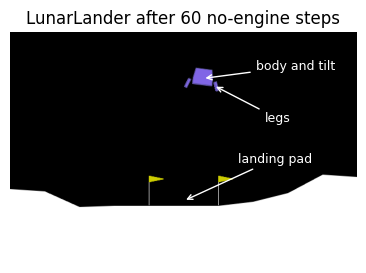

In [1]:
import os,json,time
from pathlib import Path
os.environ.setdefault('SDL_VIDEODRIVER','dummy')
os.environ.setdefault('SDL_AUDIODRIVER','dummy')
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from torch import nn
torch.set_num_threads(2)
ROOT=Path.cwd(); OUT=ROOT/'classroom_results';OUT.mkdir(exist_ok=True)
FIG=ROOT/'figures';FIG.mkdir(exist_ok=True)
started=time.perf_counter()
print('Gymnasium',gym.__version__,'; PyTorch',torch.__version__)
def save_plot(fig,name):
    for ext in ['pdf','png']:fig.savefig(FIG/(name+'.'+ext),bbox_inches='tight',dpi=160)
ENV='LunarLander-v3'
env=gym.make(ENV,render_mode='rgb_array',continuous=False,enable_wind=False)
initial,_=env.reset(seed=620)
for screenshot_step in range(60):
    screenshot_observation,_,te,tr,_=env.step(0)
    assert not(te or tr)
initial_frame=env.render()
plt.imsave(FIG/'lunarlander_environment.png',initial_frame)
print('Observation [x,y,vx,vy,angle,angular_velocity,left_contact,right_contact]:',initial)
print('Actions',env.action_space,'; time limit',env.spec.max_episode_steps)
print('Screenshot observation after 60 no-engine steps:',screenshot_observation)
fig,ax=plt.subplots(figsize=(6,3));ax.imshow(initial_frame);ax.axis('off')
ax.annotate('body and tilt',xy=(333,80),xytext=(425,65),color='white',fontsize=9,arrowprops={'arrowstyle':'->','color':'white'})
ax.annotate('legs',xy=(352,92),xytext=(440,155),color='white',fontsize=9,arrowprops={'arrowstyle':'->','color':'white'})
ax.annotate('landing pad',xy=(300,292),xytext=(395,225),color='white',fontsize=9,arrowprops={'arrowstyle':'->','color':'white'})
fig.savefig(FIG/'lunarlander_environment.png',bbox_inches='tight',dpi=160)
ax.set_title('LunarLander after 60 no-engine steps');plt.show();env.close()


## Observation, actions and reward
The policy receives eight numbers. Position $(x,y)$ is measured relative to the pad in the environment's normalised coordinates. Linear velocities are scaled environment observations. The angle and angular-velocity feature describe tilt and rotation. Two binary flags report leg contact. The rendered image supplies an illustration for the reader and is not the network input.

The four actions are 0, no engine; 1, left orientation engine; 2, main engine; 3, right orientation engine. Side engines alter orientation and horizontal motion. Their names describe the firing engine, and the resulting displacement can point the other way.

For a nonterminal transition, the reward is the change of the environment's shaping potential minus engine charges. Define
$$\Phi(s)=-100\sqrt{x^2+y^2}-100\sqrt{v_x^2+v_y^2}-100|\theta|+10c_L+10c_R.$$
The charge is 0.3 for firing the main engine and 0.03 for a side engine. The terminal step replaces this calculation by -100 for a crash or leaving the horizontal bounds, or +100 when the lander comes to rest and the physics body sleeps. The wrapper also imposes a 1000-step limit. We report that truncation separately. These statements follow the installed environment source. See the [environment specification](https://gymnasium.farama.org/environments/box2d/lunar_lander/).

This shaping is part of the task definition. With discounting, a plain difference of potentials is not automatically a policy-invariant shaping increment. The notes derive that distinction.

In [2]:
def potential(s):
    return -100*np.hypot(s[0],s[1])-100*np.hypot(s[2],s[3])-100*abs(s[4])+10*s[6]+10*s[7]
e=gym.make(ENV,continuous=False,enable_wind=False);s,_=e.reset(seed=621)
reward_checks=[]
for action in [0,2,1,3]:
    sn,r,te,tr,_=e.step(action)
    predicted=potential(sn)-potential(s)-(.3 if action==2 else .03 if action in [1,3] else 0.)
    print('action',action,'change of shaping',round(potential(sn)-potential(s),4),'reward',round(r,4),'terminal',te)
    if not te:assert np.isclose(r,predicted,atol=2e-5)
    reward_checks.append({'action':action,'reward':float(r),'nonterminal_prediction':float(predicted),'terminated':bool(te)})
    s=sn
    if te or tr:break
e.close()


action 0 change of shaping 0.2207 reward 0.2207 terminal False
action 2 change of shaping -3.1865 reward -3.4865 terminal False
action 1 change of shaping -0.6145 reward -0.6445 terminal False
action 3 change of shaping 0.7446 reward 0.7146 terminal False


## DQN values and PPO probabilities
DQN maps the eight observations to four estimates of discounted return. Its greedy controller chooses the largest output. PPO uses an actor that outputs four logits, converted to action probabilities, and a critic that estimates the policy's state value during training. The saved PPO actor alone is sufficient for acting.

PPO training reuses a batch through a clipped probability-ratio surrogate. The ratio compares a proposed policy's probability of the sampled action with the collecting policy's probability at the same state. Its advantage estimate comes from the critic. Clipping modifies the incentive in that surrogate and supplies no hard bound on the actual policy change. The full derivation is in the notes, and the complete training implementation remains in the appendix notebook.

The two checkpoints came from different training budgets, discounts and update procedures. The DQN network was trained for 200,000 environment steps with $\gamma=0.99$, a replay buffer of 100,000 transitions and a soft target-network update with $\tau=0.005$. The PPO actor was trained for 1,998,848 steps with $\gamma=0.999$. Both studies are in `appendix/`. We use the same fresh reset seeds, environment options and wrapper limit. Each agent acts deterministically for this evaluation. The PPO actor samples its actions during training and here takes its most probable action, as in the appendix evaluation.

DQN action values [71.15642 70.80931 67.56871 70.75798]
PPO probabilities [2.6862311e-01 6.6734242e-01 1.9423362e-05 6.4015001e-02]
random {'returns': [-186.4309794214584, -156.35043662966444, -257.94707154025696, -491.2284665493075, -117.57363573935244, -126.82626557592546, -2.4530460791624478, -79.0033414727309, -157.61813629005258, -70.34393321937313, -76.58530488476289, -382.0845499364873, -83.62659241238597, -457.691880508122, -218.98555142900443, -68.12320601218602, -129.9590130717666, -125.10160271731853, -83.35327154197616, -52.238543642752575], 'mean': -166.17624143370233, 'SE': 30.08067943189941, 'terminated': [True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True], 'truncated': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'terminal_rewards': [-100.0, -100.0, -100.0, -100.0, -100.0, -100.0, -100.0, -100.0, -100.0, -1

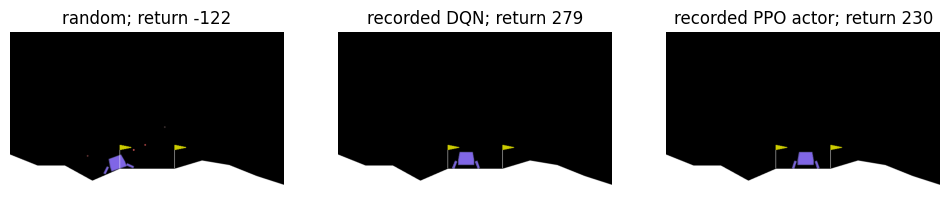

In [3]:
dqn=nn.Sequential(nn.Linear(8,256),nn.ReLU(),nn.Linear(256,256),nn.ReLU(),nn.Linear(256,4))
actor=nn.Sequential(nn.Linear(8,64),nn.Tanh(),nn.Linear(64,64),nn.Tanh(),nn.Linear(64,4))
models={}
for name,model,file in [('recorded DQN',dqn,'dqn_lunar_lander.pt'),('recorded PPO actor',actor,'ppo_actor.pt')]:
    path=ROOT/'results'/file
    if path.exists():model.load_state_dict(torch.load(path,map_location='cpu',weights_only=True));model.eval();models[name]=model
probe=torch.as_tensor(initial,dtype=torch.float32)
with torch.no_grad():
    if 'recorded DQN' in models:print('DQN action values',dqn(probe).numpy())
    if 'recorded PPO actor' in models:print('PPO probabilities',torch.softmax(actor(probe),-1).numpy())
def rollout(policy,seed,record=False):
    e=gym.make(ENV,continuous=False,enable_wind=False,render_mode='rgb_array' if record else None)
    s,_=e.reset(seed=seed);states=[];actions=[];rewards=[];frames=[];te=tr=False
    while not(te or tr):
        if record:frames.append(e.render())
        a=int(policy(s));states.append(np.array(s));actions.append(a)
        s,r,te,tr,_=e.step(a);rewards.append(float(r))
    if record:frames.append(e.render())
    e.close()
    return dict(states=np.array(states),actions=np.array(actions),rewards=np.array(rewards),
                frames=frames,terminated=bool(te),truncated=bool(tr),terminal_reward=float(rewards[-1]))
def greedy(model):
    def action(s):
        with torch.no_grad():return int(model(torch.as_tensor(s,dtype=torch.float32)).argmax())
    return action
rng=np.random.default_rng(622);policies={'random':lambda s:rng.integers(4)}
policies.update({name:greedy(model) for name,model in models.items()})
seeds=list(range(6200,6220));evaluation={}
for name,policy in policies.items():
    runs=[rollout(policy,seed) for seed in seeds];returns=[float(t['rewards'].sum()) for t in runs]
    evaluation[name]={'returns':returns,'mean':float(np.mean(returns)),
                      'SE':float(np.std(returns,ddof=1)/np.sqrt(len(returns))),
                      'terminated':[t['terminated'] for t in runs],
                      'truncated':[t['truncated'] for t in runs],
                      'terminal_rewards':[t['terminal_reward'] for t in runs],
                      'terminal_rest_events':sum(t['terminated'] and t['terminal_reward']==100 for t in runs),
                      'reached_time_limit':sum(t['truncated'] for t in runs)}
    print(name,evaluation[name])
fig,axes=plt.subplots(1,len(policies),figsize=(4*len(policies),2.7),squeeze=False)
for ax,(name,policy) in zip(axes[0],policies.items()):
    trace=rollout(policy,6200,record=True)
    ax.imshow(trace['frames'][-1]);ax.set_title(name+'; return '+str(round(trace['rewards'].sum())));ax.axis('off')
save_plot(fig,'fig_lunarlander_behaviour');plt.show()


The environment documentation counts an episode with a return of at least 200 as solved. Over the 20 fresh seeds the random policy averages $-166.2\pm30.1$, and every episode ends in a crash with the terminal reward $-100$. The saved DQN averages $252.6\pm16.7$. It ends 16 episodes at rest with the terminal reward $+100$, crashes in 2 and reaches the 1000-step limit in 2, and 16 of its returns are at least 200. The saved PPO actor averages $200.0\pm15.6$, with 15 rest events, 1 crash and 4 truncations, and 15 returns of at least 200. The two means differ by about 2.3 combined standard errors, and the agents differ in budget and training procedure, so these numbers compare two saved agents and rank no algorithms. The appendix studies report 242.3 for DQN and 229.1 for PPO over 50 other evaluation episodes, and those published values remain tied to their runs.

## A one-step TD target
For a transition $(s,a,r,s')$, the chosen DQN output is a return estimate. A one-step target adds observed reward and an estimated continuation. We inspect that calculation with the saved network. This diagnostic uses one network on both sides and performs no training. The full DQN study supplies replay memory and a separate target network.

Physical termination has zero continuation. At a wrapper cutoff the choice depends on the objective. A continuing task retains its continuation estimate, and a finite-budget task terminates at exhaustion. The appendix studies keep their recorded cutoff convention.

In [4]:
if 'recorded DQN' in models:
    e=gym.make(ENV,continuous=False,enable_wind=False);s,_=e.reset(seed=623)
    with torch.no_grad():q=dqn(torch.as_tensor(s,dtype=torch.float32))
    a=int(q.argmax());sn,r,te,tr,_=e.step(a)
    with torch.no_grad():continuation=float(dqn(torch.as_tensor(sn,dtype=torch.float32)).max())
    target=r+.99*(not te)*continuation
    print('Chosen action',a,'current estimate',float(q[a]),'reward',r,'continuation estimate',continuation,'TD target',target)
    e.close()
summary={'environment':ENV,'gymnasium':gym.__version__,'initial_observation':initial.tolist(),
         'screenshot_steps':60,'screenshot_observation':screenshot_observation.tolist(),
         'new_training':False,'evaluation_seeds':seeds,'evaluation':evaluation,
         'reward_checks':reward_checks,'runtime_seconds':time.perf_counter()-started}
(OUT/'lab062_results.json').write_text(json.dumps(summary,indent=2))
print('Core route complete. The full DQN and PPO training studies remain in appendix/.')


Chosen action 1 current estimate 99.47148132324219 reward -0.570070760382065 continuation estimate 101.17943572998047 TD target 99.5975706122986
Core route complete. The full DQN and PPO training studies remain in appendix/.


## Student calculations
Match every observation to a physical property in the screenshot. Explain why engine names and desired movement directions differ. Reconstruct a nonterminal reward from its potential change and engine charge. Distinguish a return above a chosen threshold from the terminal rest event. Compare action values with action probabilities and identify which one is a learned return estimate. Explain why equal evaluation seeds do not make different training budgets a controlled algorithm comparison.